# B13 特征很多时怎样压缩并观察结构？

使用 sklearn 自带葡萄酒数值特征，训练集拟合标准化与 PCA，独立测试集检查重构误差。图中颜色仅用于事后观察，不参与无监督拟合。

先修：B07、B11；NumPy 广播、矩阵形状、方差、线性投影。

本案例所有输入来自本地；无需联网。

**环境准备：** 下一格设置本地路径、离线模式和图表字体，直接运行即可，暂时不需要掌握所有设置。真正的解题步骤从后面的中文小节开始。

In [1]:
from pathlib import Path
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
os.environ.setdefault("TRANSFORMERS_OFFLINE", "1")
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
CASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
COURSE_ROOT = CASE_DIR.parents[1]
DATA_DIR = CASE_DIR / "data"
OUT_DIR = CASE_DIR / "outputs"
OUT_DIR.mkdir(exist_ok=True)
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "Microsoft YaHei", "axes.unicode_minus": False,
                     "figure.figsize": (8, 4.5), "figure.dpi": 110})


## 1. 理解矩阵形状
一行是一个样本，一列是一个测量值。不同单位先在训练集标准化。学习 shape、axis 与二维索引，避免把样本轴和特征轴颠倒。

In [2]:
import numpy as np,pandas as pd,json
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
dataset = load_wine(as_frame=True)
train_idx,test_idx = train_test_split(np.arange(len(dataset.data)),test_size=0.25,random_state=13,stratify=dataset.target)
scaler = StandardScaler().fit(dataset.data.iloc[train_idx])
train = scaler.transform(dataset.data.iloc[train_idx]); test = scaler.transform(dataset.data.iloc[test_idx])
assert train.shape[1] == 13
print('训练矩阵',train.shape,'测试矩阵',test.shape)


训练矩阵 (133, 13) 测试矩阵 (45, 13)


## 2. 用训练集方差决定保留维数
PCA 寻找线性变化最大的方向，不寻找最有预测价值的方向。保留累计至少 80% 的训练方差；这个比例是预先设定的教学目标，不是用测试效果挑出来的。

In [3]:
full = PCA().fit(train)
cumulative = np.cumsum(full.explained_variance_ratio_)
k = int(np.searchsorted(cumulative,0.8)+1)
pca = PCA(n_components=k).fit(train)
compressed = pca.transform(test)
assert compressed.shape == (len(test),k)


## 3. 逆变换检查丢失的信息
inverse_transform 返回标准化空间的近似原始点。与始终预测训练均值的基线比较重构误差；低重构误差不保证分类效果。先还原再查看一个样本的特征误差。

In [4]:
reconstructed = pca.inverse_transform(compressed)
baseline = np.tile(train.mean(axis=0),(len(test),1))
reconstruction_mse = float(np.mean((test-reconstructed)**2))
baseline_mse = float(np.mean((test-baseline)**2))
comparison = pd.DataFrame({'feature':dataset.feature_names,'standardized_mse':np.mean((test-reconstructed)**2,axis=0)})
assert reconstruction_mse <= baseline_mse + 1e-10


## 4. 保存方差曲线与二维投影
二维图只供观察，不能把重叠样本强行解释成明显分群。将原始标签仅作为颜色加入，表明这一步是诊断展示而非训练过程。

In [5]:
metrics = {'n_features':13,'retained_components':k,'training_variance_retained':float(cumulative[k-1]),'test_reconstruction_mse':reconstruction_mse,'mean_baseline_mse':baseline_mse}
comparison.to_csv(OUT_DIR/'feature_errors.csv',index=False)
pd.DataFrame(compressed).to_csv(OUT_DIR/'compressed_test.csv',index=False)
(OUT_DIR/'metrics.json').write_text(json.dumps(metrics,indent=2),encoding='utf-8')
fig,axes = plt.subplots(1,2,figsize=(10,4)); axes[0].plot(np.arange(1,14),cumulative,'o-'); axes[0].axhline(0.8,ls='--'); axes[0].set(xlabel='维数',ylabel='累计解释方差')
projection = full.transform(test); axes[1].scatter(projection[:,0],projection[:,1],c=dataset.target.iloc[test_idx],cmap='tab10'); axes[1].set(xlabel='PC1',ylabel='PC2')
fig.tight_layout(); fig.savefig(OUT_DIR/'pca.png'); plt.close(fig); print(metrics)


{'n_features': 13, 'retained_components': 5, 'training_variance_retained': 0.802957184592555, 'test_reconstruction_mse': 0.24244722632633586, 'mean_baseline_mse': 1.1407206931576077}


## 结果图与检查
下面展示本次计算保存的图。数值以单元格和 outputs 中的实际输出为准。

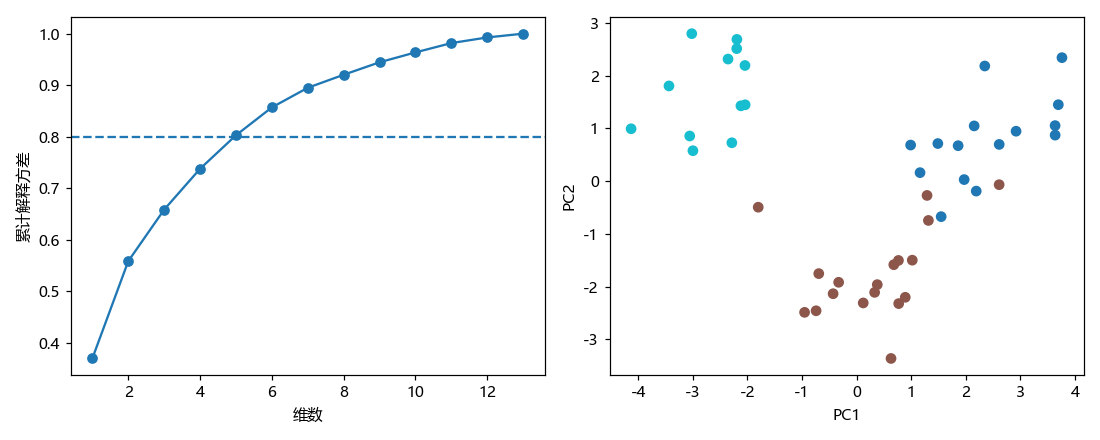

In [6]:
from IPython.display import display, Image
for figure in sorted(OUT_DIR.glob("*.png")):
    display(Image(filename=str(figure)))

## 适用边界与常见错误
PCA 方差大不等于预测有用；标准化与 PCA 都只拟合训练集。

## 独立练习
打开「动手练习.ipynb」，完成补全、修改、迁移，再查看「参考答案.ipynb」。